In [ ]:
from google.colab import drive
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd

import pylab as pl

import matplotlib.pyplot as plt
%matplotlib inline
import math
import seaborn as sns
import os

from sklearn.utils import shuffle
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    roc_curve
)
from sklearn.model_selection import cross_val_score, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.datasets import make_classification

from sklearn.preprocessing import LabelEncoder

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping


print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version: {keras.__version__}")

TensorFlow Version: 2.21.0
Keras Version: 3.13.2


In [9]:
drive.mount('/content/drive')

PASTA = Path('/content/drive/MyDrive/SensIA/rede_macro_9classes/Embeddings')

print('Pasta dos embeddings:', PASTA.resolve())

ENTRADA = 'descricao'
SEED = 42

SAIDA = PASTA.parent / 'resultados_TensorFlow_gridsearch' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')

SAIDA.mkdir(parents=True, exist_ok=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pasta dos embeddings: /content/drive/MyDrive/SensIA/rede_macro_9classes/Embeddings


### 1 Carregar e conferir a integridade

Reutilizamos as verificações de IDs, descrições, classes e vetores. A leitura do teste aqui verifica apenas integridade; seus resultados não participam da seleção. Isso não substitui revisão de rótulos ou análise de similaridade entre vídeos/canais.

In [10]:
if ENTRADA not in ('descricao', 'transcricao'):
    raise ValueError("ENTRADA deve ser 'descricao' ou 'transcricao'.")
coluna_texto = 'descricao_global' if ENTRADA == 'descricao' else 'transcricao_pronta'
colunas = [f'embedding_{i}' for i in range(1, 1025)]
dados = {}
for split in ('treino', 'validacao', 'teste'):
    arquivo = PASTA / f'embeddings_{split}_{ENTRADA}.csv'
    if not arquivo.exists():
        raise FileNotFoundError(f'Arquivo não encontrado: {arquivo}. Confira o caminho e o salvamento dos embeddings.')
    df = pd.read_csv(arquivo, dtype={'video_id': str, 'categoria': str})
    faltam = set(colunas + ['video_id', 'categoria', 'split', coluna_texto]) - set(df.columns)
    if faltam:
        raise ValueError(f'{split}: colunas ausentes: {sorted(faltam)[:8]}')
    if len(df) == 0 or df[['video_id', 'categoria', coluna_texto]].isna().any().any():
        raise ValueError(f'{split}: conjunto vazio ou ID, classe ou texto ausentes.')
    for c in ('video_id', 'categoria', coluna_texto):
        if df[c].str.strip().eq('').any():
            raise ValueError(f'{split}: campo vazio em {c}.')
    if df.video_id.duplicated().any() or not df['split'].eq(split).all():
        raise ValueError(f'{split}: vídeo duplicado ou coluna split inconsistente.')
    vetores = df[colunas].to_numpy(dtype=np.float32)
    if not np.isfinite(vetores).all() or (np.linalg.norm(vetores, axis=1) == 0).any():
        raise ValueError(f'{split}: embeddings inválidos ou vetores nulos.')
    dados[split] = df

classes = np.sort(dados['treino'].categoria.unique())
if len(classes) != 9:
    raise ValueError(f'Esperadas nove classes; encontradas {len(classes)}.')
for split, df in dados.items():
    if set(df.categoria) != set(classes):
        raise ValueError(f'{split}: precisa conter exemplos de todas as nove classes para esta avaliação.')
for a, b in [('treino', 'validacao'), ('treino', 'teste'), ('validacao', 'teste')]:
    ids_comuns = set(dados[a].video_id) & set(dados[b].video_id)
    textos_a = set(dados[a][coluna_texto].str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip())
    textos_b = set(dados[b][coluna_texto].str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip())
    if ids_comuns or textos_a & textos_b:
        raise ValueError(f'Sobreposição entre {a} e {b}. Revise os splits antes de treinar; não exclua linhas silenciosamente.')

print('Integridade básica OK. Embeddings por exemplo:', len(colunas))
display(pd.DataFrame({s: df.categoria.value_counts() for s, df in dados.items()}).loc[classes])

Integridade básica OK. Embeddings por exemplo: 1024


,treino,validacao,teste
categoria,,,
Art & Creativity,346,78,76
Automotive,362,60,78
Education,352,74,74
Entertainment,346,72,82
Hobbies & Interests,345,79,76
Lifestyle,357,72,71
News & Politics,339,77,84
Science & Technology,357,72,71
Sports,355,73,72


### 2 Transformar as categorias textuais em números inteiros de 0 a 8.

Transformamos as categorias textuais em números inteiros de 0 a 8 porque a função de perda `sparse_categorical_crossentropy`, utilizada no TensorFlow, espera que os rótulos das classes sejam representados por números inteiros.

Isso não significa que as categorias tenham uma ordem ou hierarquia. Os números são apenas identificadores das classes.

In [11]:
# Codificação das classes
encoder = LabelEncoder()
encoder.fit(classes)

X_treino = dados['treino'][colunas].to_numpy(dtype=np.float32)
X_validacao = dados['validacao'][colunas].to_numpy(dtype=np.float32)
X_teste = dados['teste'][colunas].to_numpy(dtype=np.float32)

y_treino = encoder.transform(dados['treino']['categoria'])
y_validacao = encoder.transform(dados['validacao']['categoria'])
y_teste = encoder.transform(dados['teste']['categoria'])

print("Formato de X_treino:", X_treino.shape)
print("Formato de y_treino:", y_treino.shape)
#print("Classes:", encoder.classes_)

tabela_classes = pd.DataFrame({
    'Código': range(len(encoder.classes_)),
    'Classe': encoder.classes_
})

display(tabela_classes)

Formato de X_treino: (3159, 1024)
Formato de y_treino: (3159,)


,Código,Classe
0,0,Art & Creativity
1,1,Automotive
2,2,Education
3,3,Entertainment
4,4,Hobbies & Interests
5,5,Lifestyle
6,6,News & Politics
7,7,Science & Technology
8,8,Sports


### 3 GridSearch

In [12]:
# Hiperparâmetros
valores_neuronios_1 = [32, 64, 128]
valores_neuronios_2 = [32, 64, 128]
valores_l2 = [0, 0.0001, 0.001, 0.01, 0.1]

A função recebe os tamanhos das duas camadas ocultas e a regularização L2. A rede processa embeddings de 1.024 dimensões e produz probabilidades para nove temas. Configuramos Adam para atualizar os pesos e entropia cruzada para medir o erro. Essa função permite construir cada configuração testada no GridSearch.

In [13]:
def criar_modelo(neuronios_1, neuronios_2, valor_l2):

    regularizador = (
        keras.regularizers.l2(valor_l2)
        if valor_l2 > 0 else None
    )

    model = keras.Sequential([
        keras.Input(shape=(X_treino.shape[1],)),

        layers.Dense(
            neuronios_1,
            activation='relu',
            kernel_regularizer=regularizador
        ),

        layers.Dense(
            neuronios_2,
            activation='relu',
            kernel_regularizer=regularizador
        ),

        layers.Dense(9, activation='softmax')
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0001),
        loss='sparse_categorical_crossentropy', #Mede o erro da rede considerando as probabilidades previstas.
        metrics=[
          keras.metrics.SparseCategoricalAccuracy(name='accuracy')
        ]
    )

    return model

In [14]:
resultados = []

combinacoes = [
    (n1, n2, l2)
    for n1 in valores_neuronios_1
    for n2 in valores_neuronios_2
    for l2 in valores_l2
]

for i, (n1, n2, l2) in enumerate(combinacoes, start=1):

    print(f"Experimento {i}/{len(combinacoes)}")
    print(f"Neurônios: ({n1}, {n2}) | L2: {l2}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = criar_modelo(n1, n2, l2)

    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_treino,
        y_treino,
        epochs=100,
        batch_size=32,
        validation_data=(X_validacao, y_validacao),
        callbacks=[early_stopping],
        verbose=1
    )

    # Previsões na validação
    probabilidades = model.predict(X_validacao, verbose=0)
    previsoes_validacao = np.argmax(probabilidades, axis=1)

    # F1-score macro
    f1_macro = f1_score(
        y_validacao,
        previsoes_validacao,
        average='macro'
    )

    resultados.append({
        'Neuronios_1': n1,
        'Neuronios_2': n2,
        'L2': l2,
        'F1_macro': f1_macro,
        'Accuracy_validacao': np.mean(
            previsoes_validacao == y_validacao
        ),
        'Menor_val_loss': min(history.history['val_loss']),
        'Epocas': len(history.history['loss'])
    })

# Organizar resultados
df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by='F1_macro',
    ascending=False
).reset_index(drop=True)

display(df_resultados.round(4))

A saída de streaming foi truncada nas últimas 5000 linhas.
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2507 - loss: 2.4935 - val_accuracy: 0.1933 - val_loss: 2.4690
Epoch 21/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2412 - loss: 2.4458 - val_accuracy: 0.1903 - val_loss: 2.4248
Epoch 22/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2257 - loss: 2.4046 - val_accuracy: 0.1887 - val_loss: 2.3867
Epoch 23/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2153 - loss: 2.3692 - val_accuracy: 0.1903 - val_loss: 2.3540
Epoch 24/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2086 - loss: 2.3390 - val_accuracy: 0.1903 - val_loss: 2.3262
Epoch 25/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2064 - loss: 2.3133 - val_accuracy: 0.1933 - val_loss: 2.3026
Epoch 26/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2026 - loss: 2.2916 - val_accuracy: 0.1933 - val_loss: 2.2828
Epoch 27/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accu

,Neuronios_1,Neuronios_2,L2,F1_macro,Accuracy_validacao,Menor_val_loss,Epocas
0,128,32,0.0000,0.6479,0.6514,1.0659,60
1,128,32,0.0001,0.6417,0.6454,1.1257,57
2,128,64,0.0000,0.6417,0.6454,1.0580,48
3,128,128,0.0010,0.6410,0.6469,1.3512,57
4,64,32,0.0010,0.6404,0.6423,1.3227,100
5,64,128,0.0000,0.6390,0.6423,1.0637,53
6,128,64,0.0010,0.6377,0.6438,1.3371,66
7,128,32,0.0010,0.6377,0.6423,1.3368,88
8,128,64,0.0001,0.6374,0.6408,1.1140,47
9,32,128,0.0010,0.6369,0.6423,1.2700,73


Esse bloco abaixo realiza uma busca em grade manual (GridSearch), testando todas as combinações das quantidades de neurônios das duas camadas ocultas e dos valores de regularização L2.
Antes de cada experimento, limpa o estado do Keras e define a semente 42 para favorecer a reprodutibilidade.
Cada combinação cria uma rede nova, treinada em lotes de 32 exemplos por até 100 épocas. O EarlyStopping acompanha a perda de validação, interrompe o treinamento após dez épocas consecutivas sem melhora e restaura os pesos da época com a menor perda. Em seguida, a rede calcula as probabilidades dos exemplos de validação, e a classe com maior probabilidade é utilizada como previsão. O código calcula o F1 macro, que atribui o mesmo peso às nove classes, e registra os parâmetros, a acurácia, a menor perda de validação e a quantidade de épocas executadas. Por fim, organiza os resultados em uma tabela ordenada do maior para o menor F1 macro, permitindo identificar a configuração com melhor desempenho na validação sem utilizar o conjunto de teste nessa escolha.

In [15]:
melhor_resultado = df_resultados.iloc[0]

print("Melhor configuração:")
print(melhor_resultado)

Melhor configuração:
Neuronios_1           128.000000
Neuronios_2            32.000000
L2                      0.000000
F1_macro                0.647936
Accuracy_validacao      0.651446
Menor_val_loss          1.065901
Epocas                 60.000000
Name: 0, dtype: float64


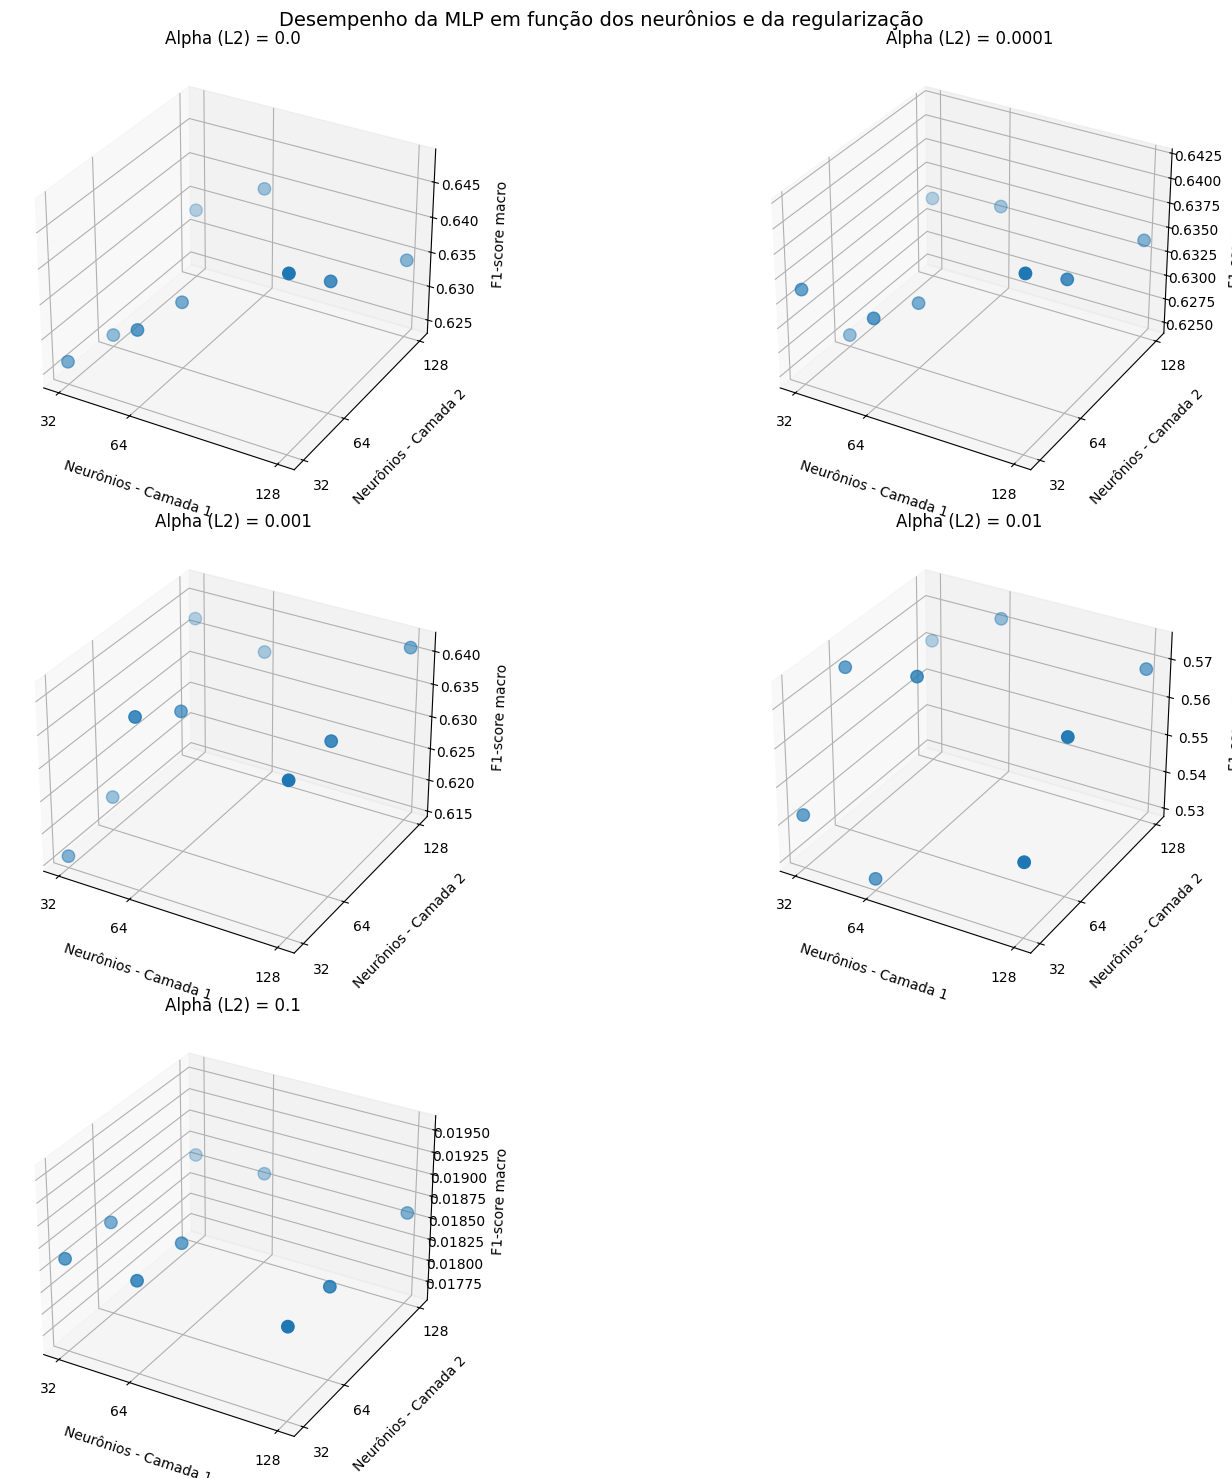

In [16]:
valores_l2 = sorted(df_resultados['L2'].unique())

n_graficos = len(valores_l2)
n_colunas = 2
n_linhas = math.ceil(n_graficos / n_colunas)

fig = plt.figure(figsize=(16, 5 * n_linhas))

for i, alpha in enumerate(valores_l2, start=1):

    ax = fig.add_subplot(n_linhas, n_colunas, i, projection='3d')

    resultados = df_resultados[df_resultados['L2'] == alpha]

    ax.scatter(
        resultados['Neuronios_1'],
        resultados['Neuronios_2'],
        resultados['F1_macro'],
        marker='o',
        s=80
    )

    ax.set_xlabel('Neurônios - Camada 1', labelpad=10)
    ax.set_ylabel('Neurônios - Camada 2', labelpad=10)
    ax.set_zlabel('F1-score macro', labelpad=10)

    ax.set_xticks([32, 64, 128])
    ax.set_yticks([32, 64, 128])

    ax.set_title(f'Alpha (L2) = {alpha}')

fig.suptitle(
    'Desempenho da MLP em função dos neurônios e da regularização',
    fontsize=14
)

plt.tight_layout()
plt.show()

Esse bloco acima apresenta os resultados da busca em grade em gráficos tridimensionais, separados por valor de regularização L2.
Cada ponto representa uma combinação das quantidades de neurônios das duas camadas ocultas, e sua posição vertical indica o F1 macro obtido na validação. Os resultados mostram que aumentar a quantidade de neurônios ou a intensidade da regularização não garantiu melhor desempenho. A configuração com 128 e 32 neurônios, sem penalização L2, apresentou o maior F1 macro, aproximadamente 0,6479. Valores elevados de L2 prejudicaram o desempenho neste experimento. Como cada painel possui uma escala vertical própria, a comparação entre os gráficos deve considerar os valores numéricos do F1, e não apenas a altura visual dos pontos.

### 4  Treinar a configuração selecionada

- n° de neurônios na camada oculta 1: 128
- n° de neurônios na camada oculta 2: 32
- L2: 0 ( sem regularização)

In [17]:
# Recuperar automaticamente a configuração vencedora do GridSearch
melhor_resultado = df_resultados.iloc[0]

n1 = int(melhor_resultado['Neuronios_1'])
n2 = int(melhor_resultado['Neuronios_2'])
valor_l2 = float(melhor_resultado['L2'])

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

modelo_final = criar_modelo(
    neuronios_1=n1,
    neuronios_2=n2,
    valor_l2=valor_l2
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

historico = modelo_final.fit(
    X_treino,
    y_treino,
    epochs=100,
    batch_size=32,
    validation_data=(X_validacao, y_validacao),
    callbacks=[early_stopping],
    verbose=1
)

melhor_epoca_sem_dropout = (
    int(np.argmin(historico.history['val_loss'])) + 1
)

print(f'Camadas ocultas: {n1} e {n2} neurônios')
print(f'L2: {valor_l2}')
print(f'Épocas executadas: {len(historico.history["loss"])}')
print(f'Melhor época: {melhor_epoca_sem_dropout}')

modelo_final.summary()

Epoch 1/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1956 - loss: 2.1830 - val_accuracy: 0.2405 - val_loss: 2.1653
Epoch 2/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3254 - loss: 2.1352 - val_accuracy: 0.3775 - val_loss: 2.1053
Epoch 3/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4685 - loss: 2.0550 - val_accuracy: 0.5023 - val_loss: 2.0192
Epoch 4/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5362 - loss: 1.9536 - val_accuracy: 0.5449 - val_loss: 1.9217
Epoch 5/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5685 - loss: 1.8388 - val_accuracy: 0.5647 - val_loss: 1.8147
Epoch 6/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5752 - loss: 1.7198 - val_accuracy: 0.5693 - val_loss: 1.7106
Epoch 7/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5882 - loss: 1.6072 - val_accuracy: 0.5753 - val_loss: 1.6151
Epoch 8/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5989 - loss: 1.5064 - val_accuracy: 0.5890 - v

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 406,877 (1.55 MB)

 Trainable params: 135,625 (529.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 271,252 (1.03 MB)

In [20]:
# Avaliar no treinamento
probs_treino = modelo_final.predict(X_treino, verbose=0)

previsoes_treino = np.argmax(probs_treino, axis=1)

print('Métricas do treinamento:')
print(classification_report(
    y_treino,
    previsoes_treino,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Métricas do treinamento:
                      precision    recall  f1-score   support

    Art & Creativity       0.82      0.80      0.81       346
          Automotive       0.83      0.95      0.89       362
           Education       0.68      0.56      0.61       352
       Entertainment       0.68      0.71      0.70       346
 Hobbies & Interests       0.66      0.65      0.66       345
           Lifestyle       0.82      0.82      0.82       357
     News & Politics       0.79      0.82      0.81       339
Science & Technology       0.81      0.87      0.84       357
              Sports       0.82      0.76      0.79       355

            accuracy                           0.77      3159
           macro avg       0.77      0.77      0.77      3159
        weighted avg       0.77      0.77      0.77      3159



In [21]:
# Avaliar na validação
probs_validacao = modelo_final.predict(X_validacao, verbose=0)

previsoes_validacao = np.argmax(probs_validacao, axis=1)

print('Métricas da validação:')
print(classification_report(
    y_validacao,
    previsoes_validacao,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Métricas da validação:
                      precision    recall  f1-score   support

    Art & Creativity       0.82      0.87      0.84        78
          Automotive       0.82      0.97      0.89        60
           Education       0.43      0.31      0.36        74
       Entertainment       0.56      0.56      0.56        72
 Hobbies & Interests       0.51      0.48      0.49        79
           Lifestyle       0.63      0.64      0.63        72
     News & Politics       0.68      0.68      0.68        77
Science & Technology       0.71      0.79      0.75        72
              Sports       0.63      0.63      0.63        73

            accuracy                           0.65       657
           macro avg       0.64      0.66      0.65       657
        weighted avg       0.64      0.65      0.64       657



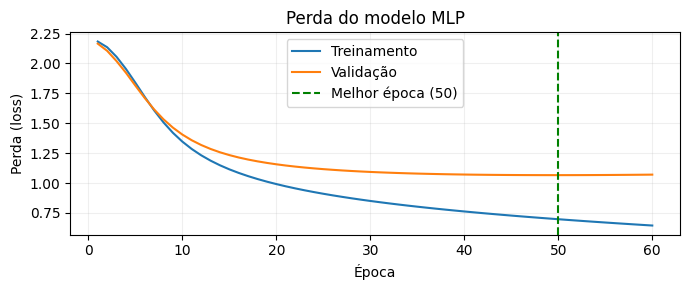

Melhor época: 50
Menor val_loss: 1.0659


In [22]:
# Identificar a melhor época pela menor perda de validação
melhor_epoca = np.argmin(historico.history['val_loss']) + 1

# Criar gráfico
fig, ax = plt.subplots(figsize=(7, 3))

epocas = range(1, len(historico.history['loss']) + 1)

ax.plot(
    epocas,
    historico.history['loss'],
    label='Treinamento'
)

ax.plot(
    epocas,
    historico.history['val_loss'],
    label='Validação'
)

# Linha vertical indicando a melhor época
ax.axvline(
    x=melhor_epoca,
    color='green',
    linestyle='--',
    label=f'Melhor época ({melhor_epoca})'
)

ax.set(
    title='Perda do modelo MLP',
    xlabel='Época',
    ylabel='Perda (loss)'
)

ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    SAIDA / 'perda_treino_validacao.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

print(f'Melhor época: {melhor_epoca}')
print(f'Menor val_loss: {min(historico.history["val_loss"]):.4f}')

A curva de perda apresentou uma redução contínua da função de perda nos dados de treinamento, enquanto a perda de validação diminuiu inicialmente e, posteriormente, apresentou tendência de estabilização. Esse comportamento indica que o modelo está aaprendendo padrões específicos dos dados de treinamento e não apresenta melhorias proporcionais na capacidade de generalização.

**DROPOUT**

A utilização do Dropout foi motivada pelos sinais de overfitting identificados durante o treinamento da MLP.

O Dropout é uma técnica de regularização utilizada em redes neurais que consiste em desativar aleatoriamente uma proporção dos neurônios durante cada etapa do treinamento. Com isso, a rede não depende excessivamente de determinados neurônios para realizar as classificações, sendo incentivada a aprender representações mais distribuídas entre as unidades da arquitetura. Durante a avaliação e a predição, todos os neurônios são utilizados normalmente.

Para investigar o efeito dessa técnica no desempenho do modelo, foi realizado um experimento com a taxa de Dropout igual a 0,4.

Embora o Dropout de 0,4 tenha apresentado uma pequena melhora em algumas categorias, seu F1-score macro na validação foi de 0,65, igual ao obtido pelo modelo sem Dropout. Além disso, a inclusão do Dropout não proporcionou uma redução consistente da diferença entre as métricas de treinamento e validação.

In [23]:
# Mesma configuração vencedora, acrescentando apenas Dropout
tf.keras.utils.set_random_seed(SEED)

regularizador = (
    keras.regularizers.l2(valor_l2)
    if valor_l2 > 0 else None
)

modelo_finaldp = keras.Sequential([
    keras.Input(shape=(X_treino.shape[1],)),

    layers.Dense(
        n1,
        activation='relu',
        kernel_regularizer=regularizador
    ),
    layers.Dropout(0.4),

    layers.Dense(
        n2,
        activation='relu',
        kernel_regularizer=regularizador
    ),
    layers.Dropout(0.4),

    layers.Dense(len(encoder.classes_), activation='softmax')
])

modelo_finaldp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name='accuracy')
    ]
)

early_stopping_dp = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

historicodp = modelo_finaldp.fit(
    X_treino,
    y_treino,
    epochs=100,
    batch_size=32,
    validation_data=(X_validacao, y_validacao),
    callbacks=[early_stopping_dp],
    verbose=1
)

Epoch 1/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.1504 - loss: 2.1909 - val_accuracy: 0.2253 - val_loss: 2.1852
Epoch 2/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1985 - loss: 2.1728 - val_accuracy: 0.3166 - val_loss: 2.1608
Epoch 3/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2510 - loss: 2.1411 - val_accuracy: 0.4170 - val_loss: 2.1258
Epoch 4/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2840 - loss: 2.0998 - val_accuracy: 0.4581 - val_loss: 2.0814
Epoch 5/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3197 - loss: 2.0534 - val_accuracy: 0.4658 - val_loss: 2.0294
Epoch 6/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3270 - loss: 2.0100 - val_accuracy: 0.4962 - val_loss: 1.9730
Epoch 7/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3710 - loss: 1.9499 - val_accuracy: 0.5114 - val_loss: 1.9105
Epoch 8/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3884 - loss: 1.8938 - val_accuracy: 0.5342 - v

In [24]:
# Avaliar no treinamento
probs_treinodp = modelo_finaldp.predict(X_treino, verbose=0)

previsoes_treinodp = np.argmax(probs_treinodp, axis=1)

print('Métricas do treinamento:')
print(classification_report(
    y_treino,
    previsoes_treinodp,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Métricas do treinamento:
                      precision    recall  f1-score   support

    Art & Creativity       0.83      0.86      0.84       346
          Automotive       0.84      0.98      0.91       362
           Education       0.75      0.55      0.63       352
       Entertainment       0.68      0.74      0.71       346
 Hobbies & Interests       0.74      0.64      0.69       345
           Lifestyle       0.82      0.83      0.83       357
     News & Politics       0.81      0.84      0.82       339
Science & Technology       0.81      0.88      0.84       357
              Sports       0.85      0.82      0.83       355

            accuracy                           0.79      3159
           macro avg       0.79      0.79      0.79      3159
        weighted avg       0.79      0.79      0.79      3159



In [25]:
# Avaliar na validação
probs_validacaodp = modelo_finaldp.predict(X_validacao, verbose=0)

previsoes_validacaodp = np.argmax(probs_validacaodp, axis=1)

print('Métricas da validação:')
print(classification_report(
    y_validacao,
    previsoes_validacaodp,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Métricas da validação:
                      precision    recall  f1-score   support

    Art & Creativity       0.80      0.86      0.83        78
          Automotive       0.84      0.97      0.90        60
           Education       0.46      0.30      0.36        74
       Entertainment       0.54      0.60      0.57        72
 Hobbies & Interests       0.48      0.44      0.46        79
           Lifestyle       0.64      0.68      0.66        72
     News & Politics       0.63      0.65      0.64        77
Science & Technology       0.72      0.81      0.76        72
              Sports       0.67      0.62      0.64        73

            accuracy                           0.65       657
           macro avg       0.64      0.66      0.65       657
        weighted avg       0.64      0.65      0.64       657



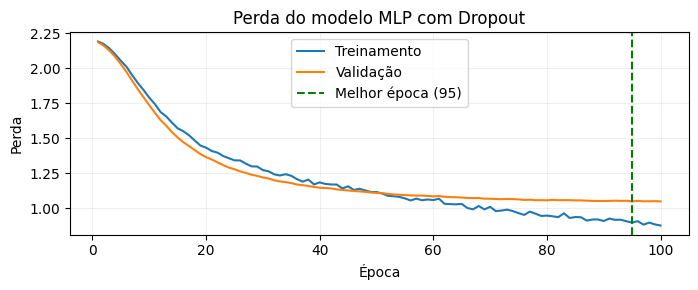

Melhor época: 95
Menor val_loss: 1.0480


In [26]:
melhor_epoca_dropout = (
    int(np.argmin(historicodp.history['val_loss'])) + 1
)

fig, ax = plt.subplots(figsize=(7, 3))

epocas = range(1, len(historicodp.history['loss']) + 1)

ax.plot(
    epocas,
    historicodp.history['loss'],
    label='Treinamento'
)

ax.plot(
    epocas,
    historicodp.history['val_loss'],
    label='Validação'
)

ax.axvline(
    melhor_epoca_dropout,
    color='green',
    linestyle='--',
    label=f'Melhor época ({melhor_epoca_dropout})'
)

ax.set(
    title='Perda do modelo MLP com Dropout',
    xlabel='Época',
    ylabel='Perda'
)

ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    SAIDA / 'perda_treino_validacao_dropout.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

print(f'Melhor época: {melhor_epoca_dropout}')
print(
    f'Menor val_loss: '
    f'{min(historicodp.history["val_loss"]):.4f}'
)

In [27]:
# Comparar somente pela validação
comparacao_modelos = []

for nome, modelo in [
    ('Sem Dropout', modelo_final),
    ('Dropout 0.4', modelo_finaldp)
]:
    probabilidades_val = modelo.predict(
        X_validacao,
        verbose=0
    )
    previsoes_val = np.argmax(probabilidades_val, axis=1)

    comparacao_modelos.append({
        'modelo': nome,
        'f1_macro_validacao': f1_score(
            y_validacao,
            previsoes_val,
            average='macro',
            zero_division=0
        ),
        'acuracia_validacao': accuracy_score(
            y_validacao,
            previsoes_val
        )
    })

comparacao_modelos = pd.DataFrame(comparacao_modelos)

display(comparacao_modelos.round(4))

comparacao_modelos.to_csv(
    SAIDA / 'comparacao_dropout.csv',
    index=False
)

,modelo,f1_macro_validacao,acuracia_validacao
0,Sem Dropout,0.6479,0.6514
1,Dropout 0.4,0.6463,0.6499


### 5 Avaliação final do teste

Optou-se por manter o modelo sem Dropout. Como as técnicas de regularização testadas não proporcionaram ganhos consistentes no desempenho de validação, sua utilização não se mostrou vantajosa nos experimentos realizados. Portanto, foi mantido o modelo mais simples, que apresentou desempenho de validação equivalente ou superior às alternativas regularizadas.

In [28]:
# 1. Preparar os dados de teste
X_teste = dados['teste'][colunas].to_numpy(dtype=np.float32)

# Codificar as classes utilizando o LabelEncoder já ajustado no treino
y_teste = encoder.transform(dados['teste']['categoria'])

# 2. Obter as probabilidades previstas pela MLP
probabilidades = modelo_final.predict(X_teste, verbose=0)

# Ordem das classes nas colunas de probabilidades
classes_modelo = np.arange(len(encoder.classes_))

# 3. Obter as classes previstas
previsoes = classes_modelo[probabilidades.argmax(axis=1)]

# 4. Criar o modelo baseline
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_treino, y_treino)

previsoes_base = baseline.predict(X_teste)

# 5. Calcular ROC-AUC macro OVR
auc_macro = roc_auc_score(
    y_teste,
    probabilidades,
    labels=classes_modelo,
    multi_class='ovr',
    average='macro'
)

# 6. Comparar os modelos
resumo = pd.DataFrame([
    {
        'modelo': 'Classe mais frequente',
        'acuracia': accuracy_score(y_teste, previsoes_base),
        'f1_macro': f1_score(
            y_teste, previsoes_base,
            average='macro',
            zero_division=0
        ),
        'roc_auc_macro_ovr': np.nan
    },
    {
        'modelo': 'MLP TensorFlow BGE-M3',
        'acuracia': accuracy_score(y_teste, previsoes),
        'f1_macro': f1_score(
            y_teste, previsoes,
            average='macro',
            zero_division=0
        ),
        'roc_auc_macro_ovr': auc_macro
    }
])

# 7. Relatório de classificação da MLP
relatorio = pd.DataFrame(
    classification_report(
        y_teste,
        previsoes,
        labels=classes_modelo,
        target_names=encoder.classes_,
        output_dict=True,
        zero_division=0
    )
).T

# 8. Exibir resultados
print('Resultados finais no conjunto de teste:')

display(resumo.round(4))

print('Relatório de classificação da MLP:')
display(relatorio.round(4))

Resultados finais no conjunto de teste:


,modelo,acuracia,f1_macro,roc_auc_macro_ovr
0,Classe mais frequente,0.114,0.0227,NaN
1,MLP TensorFlow BGE-M3,0.617,0.6107,0.9121


Relatório de classificação da MLP:


,precision,recall,f1-score,support
Art & Creativity,0.7027,0.6842,0.6933,76.000
Automotive,0.7738,0.8333,0.8025,78.000
Education,0.4262,0.3514,0.3852,74.000
Entertainment,0.4605,0.4268,0.4430,82.000
Hobbies & Interests,0.4933,0.4868,0.4901,76.000
Lifestyle,0.5303,0.4930,0.5109,71.000
News & Politics,0.6842,0.7738,0.7263,84.000
Science & Technology,0.7000,0.7887,0.7417,71.000
Sports,0.6986,0.7083,0.7034,72.000
accuracy,0.6170,0.6170,0.6170,0.617


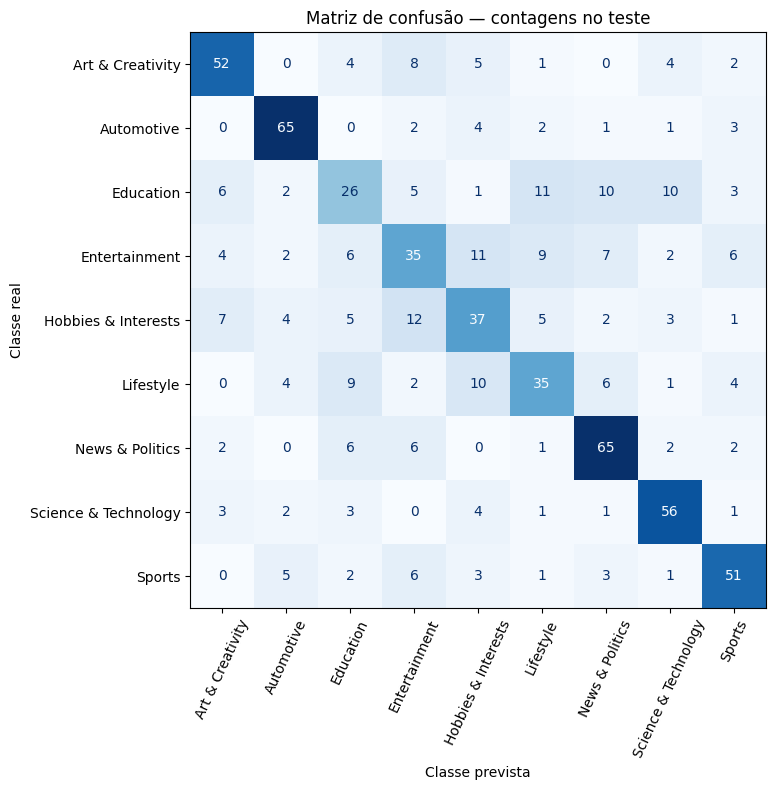

In [29]:
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes,
    labels=classes_modelo,
    display_labels=encoder.classes_,
    cmap='Blues',
    colorbar=False,
    ax=ax,
    xticks_rotation=65
)

ax.set(
    title='Matriz de confusão — contagens no teste',
    xlabel='Classe prevista',
    ylabel='Classe real'
)

fig.tight_layout()

fig.savefig(
    SAIDA / 'matriz_confusao.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

### 6 Curva ROC-AUC separada para cada classe

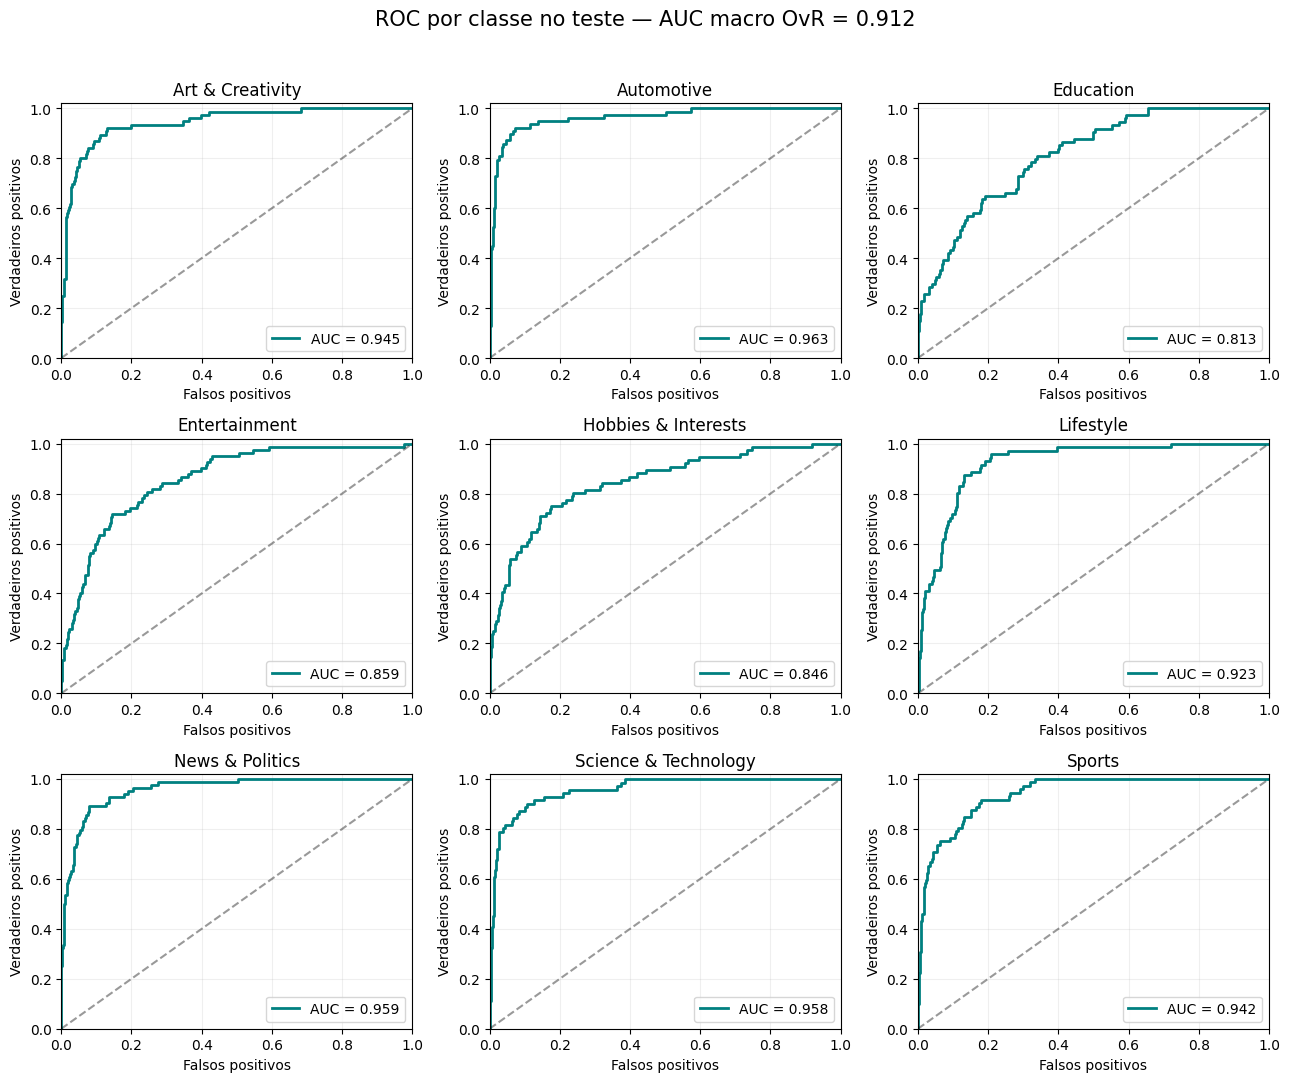

,classe,auc_ovr,exemplos_teste
0,Art & Creativity,0.9447,76
1,Automotive,0.9634,78
2,Education,0.8126,74
3,Entertainment,0.8589,82
4,Hobbies & Interests,0.8465,76
5,Lifestyle,0.9233,71
6,News & Politics,0.9590,84
7,Science & Technology,0.9584,71
8,Sports,0.9421,72


In [30]:
# Probabilidades previstas pelo modelo para cada classe
probabilidades = modelo_final.predict(X_teste, verbose=0)

# Classes codificadas pelo LabelEncoder
classes_modelo = np.arange(len(encoder.classes_))

fig, eixos = plt.subplots(3, 3, figsize=(13, 11))
aucs = []

for i, (classe, ax) in enumerate(zip(classes_modelo, eixos.flat)):

    # Abordagem One-vs-Rest (OvR)
    y_binario = (y_teste == classe).astype(int)

    # Curva ROC e AUC da classe
    fpr, tpr, _ = roc_curve(y_binario, probabilidades[:, i])
    auc_classe = roc_auc_score(y_binario, probabilidades[:, i])

    aucs.append({
        'classe': encoder.classes_[classe],
        'auc_ovr': auc_classe,
        'exemplos_teste': int(y_binario.sum())
    })

    # Gráfico na figura com as nove classes
    ax.plot(fpr, tpr, color='teal', linewidth=2,
            label=f'AUC = {auc_classe:.3f}')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)

    ax.set(
        title=encoder.classes_[classe],
        xlabel='Falsos positivos',
        ylabel='Verdadeiros positivos',
        xlim=(0, 1),
        ylim=(0, 1.02)
    )

    ax.legend(loc='lower right')
    ax.grid(alpha=0.2)

    # Figura individual por classe
    fig_ind, ax_ind = plt.subplots(figsize=(5, 4))

    ax_ind.plot(fpr, tpr, color='teal',
                label=f'AUC = {auc_classe:.3f}')
    ax_ind.plot([0, 1], [0, 1], 'k--', alpha=0.4)

    ax_ind.set(
        title=f'ROC — {encoder.classes_[classe]}',
        xlabel='Falsos positivos',
        ylabel='Verdadeiros positivos',
        xlim=(0, 1),
        ylim=(0, 1.02)
    )

    ax_ind.legend()
    ax_ind.grid(alpha=0.2)
    fig_ind.tight_layout()

    fig_ind.savefig(
        SAIDA / f'roc_classe_{i+1:02d}.png',
        dpi=160,
        bbox_inches='tight'
    )

    plt.close(fig_ind)

# Figura geral
fig.suptitle(
    f'ROC por classe no teste — AUC macro OvR = {auc_macro:.3f}',
    fontsize=15
)

fig.tight_layout(rect=(0, 0, 1, 0.96))

fig.savefig(
    SAIDA / 'roc_nove_classes.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

# Tabela com AUC por classe
aucs = pd.DataFrame(aucs)
display(aucs.round(4))

In [31]:
import json

# Modelo escolhido: sem Dropout
modelo_final.save(
    SAIDA / 'modelo_mlp_tensorflow.keras'
)

# Ordem das classes: necessária para interpretar as previsões
(SAIDA / 'classes.json').write_text(
    json.dumps(
        encoder.classes_.tolist(),
        ensure_ascii=False,
        indent=2
    ),
    encoding='utf-8'
)

# Configuração para rastreabilidade e integração
configuracao = {
    'encoder_embeddings': 'BAAI/bge-m3',
    'entrada': ENTRADA,
    'dimensoes': int(X_treino.shape[1]),
    'colunas_embeddings': colunas,
    'neuronios_1': n1,
    'neuronios_2': n2,
    'l2': valor_l2,
    'dropout': 0.0,
    'learning_rate': 0.0001,
    'batch_size': 32,
    'max_epocas': 100,
    'patience': 10,
    'semente': SEED,
    'melhor_epoca': melhor_epoca_sem_dropout,
    'tensorflow': tf.__version__
}

(SAIDA / 'configuracao.json').write_text(
    json.dumps(configuracao, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

df_resultados.to_csv(
    SAIDA / 'gridsearch.csv',
    index=False
)

resumo.to_csv(
    SAIDA / 'metricas_teste.csv',
    index=False
)

relatorio.to_csv(
    SAIDA / 'relatorio_classes.csv',
    encoding='utf-8-sig'
)

aucs.to_csv(
    SAIDA / 'auc_por_classe.csv',
    index=False
)

pd.DataFrame(historico.history).to_csv(
    SAIDA / 'historico_sem_dropout.csv',
    index=False
)

pd.DataFrame(historicodp.history).to_csv(
    SAIDA / 'historico_dropout.csv',
    index=False
)

print('Modelo e resultados salvos em:', SAIDA)

Modelo e resultados salvos em: /content/drive/MyDrive/SensIA/rede_macro_9classes/resultados_TensorFlow_gridsearch/20261110_171317_382674
